# 01 – Explore UCI garment productivity data
Source: Imran, Rahim & Ahmed (2021), "Mining the productivity data of the garment industry",
Int. J. Business Intelligence and Data Mining. UCI dataset 597, DOI 10.24432/C51S6D, CC BY 4.0.
Purpose: realism benchmarks for the sewing-line model (not direct model input).

### Environment check
Confirm which Python interpreter the kernel uses and the pandas version, so results can be reproduced.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

print(sys.executable)
print(pd.__version__)

f:\ML Projects\Lean and Green Project\lean-green-sewing-line\.venv\Scripts\python.exe
3.0.6


### Load the data
Read the UCI CSV into a DataFrame. `df.shape` gives (rows, columns): one row is one team on one day.

In [2]:
df = pd.read_csv("../data/garments_worker_productivity.csv")
print(df.shape)
df.head()

(1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


### Column types and non-null counts
`info()` shows each column's type and how many values are present — a quick way to spot missing data and columns read as the wrong type (e.g. `date` as text).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

### Missing values and departments
Count missing values per column, then count rows per department. This reveals two problems fixed in the next cell: `wip` is missing for many rows, and the department names are misspelled/padded (`"sweing"`, `"finishing "`).

In [4]:
print(df.isna().sum())
df["department"].value_counts()

date                       0
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
dtype: int64


department
sweing        691
finishing     257
finishing     249
Name: count, dtype: int64

### Clean and keep only sewing
- `str.strip()` removes trailing spaces; `"sweing"` is renamed to `"sewing"`.
- `date` is converted from text (`m/d/Y`) to real dates.
- Keep only sewing rows (`sew`). WIP is only recorded for sewing, so `sew` should have no missing `wip`.

In [5]:
df["department"] = df["department"].str.strip().replace({"sweing": "sewing"})
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
print(df["department"].value_counts())

sew = df[df["department"] == "sewing"].copy()
print(sew.shape, "| missing wip:", sew["wip"].isna().sum())
print("date range:", sew["date"].min().date(), "to", sew["date"].max().date())

department
sewing       691
finishing    506
Name: count, dtype: int64
(691, 15) | missing wip: 0
date range: 2015-01-01 to 2015-03-11


### Summary statistics
Count, mean, std, min, quartiles and max for the columns relevant to the model (`.T` turns columns into rows for easier reading).
- `smv` = standard minute value: minutes a trained operator needs for one garment.
- `targeted_productivity` / `actual_productivity` are on a 0–1 scale.

In [6]:
cols = ["no_of_workers", "smv", "wip", "idle_time", "idle_men",
        "targeted_productivity", "actual_productivity"]
sew[cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
no_of_workers,691.0,52.45,9.42,26.00,52.00,57.00,58.00,89.00
smv,691.0,23.25,6.98,10.05,18.79,22.52,28.08,54.56
wip,691.0,1190.47,1837.46,7.00,774.50,1039.00,1252.50,23122.00
idle_time,691.0,1.26,16.71,0.00,0.00,0.00,0.00,300.00
idle_men,691.0,0.64,4.28,0.00,0.00,0.00,0.00,45.00
targeted_productivity,691.0,0.72,0.10,0.07,0.70,0.75,0.80,0.80
actual_productivity,691.0,0.72,0.15,0.23,0.66,0.75,0.80,1.10


### How often teams miss target or stand idle
Productivity gap per team-day:

$$\text{gap} = \text{actual productivity} - \text{targeted productivity}$$

`(gap < 0).mean()` is the share of team-days below target (True = 1, False = 0, so the mean is a fraction). Same idea for team-days with any idle time.

In [7]:
sew["gap"] = sew["actual_productivity"] - sew["targeted_productivity"]
print("team-days below target:", round((sew["gap"] < 0).mean() * 100, 1), "%")
print("team-days with any idle time:", round((sew["idle_time"] > 0).mean() * 100, 1), "%")

team-days below target: 17.1 %
team-days with any idle time: 2.6 %


### Histogram: UCI productivity vs. model efficiency
Distribution of actual productivity across 691 sewing team-days, with the median marked. The dashed lines are the model's line efficiencies (from `src/balancing.py`):

$$\text{line efficiency} = \frac{\sum \text{SMV}}{\text{operators} \times \text{cycle time}}$$

- Model A: $5.6 / (10 \times 0.90) = 0.62$
- Model B: $5.6 / (12 \times 0.60) = 0.78$

This shows whether the model's efficiencies sit in a realistic range. The figure is saved to `results/figures/`.

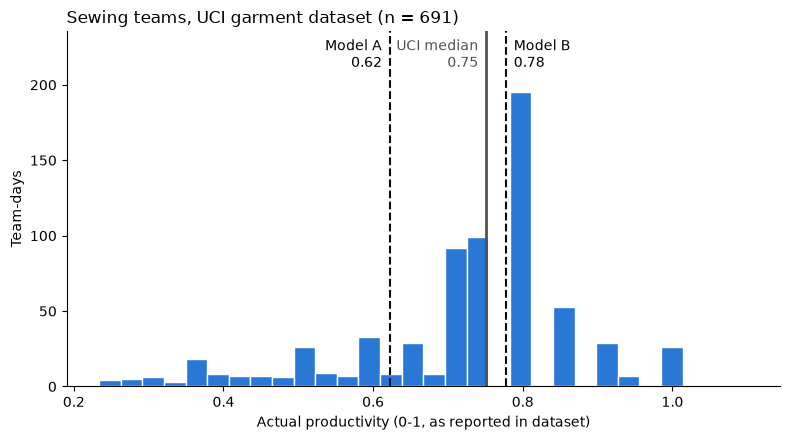

In [8]:
median = sew["actual_productivity"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sew["actual_productivity"], bins=30, color="#2a78d6", edgecolor="white", linewidth=1)
top = ax.get_ylim()[1] * 1.15          # extra room above the bars for the labels
ax.set_ylim(0, top)

# UCI median (solid line)
ax.axvline(median, color="#52514e", linewidth=2)
ax.text(median - 0.01, top * 0.90, f"UCI median\n{median:.2f}", ha="right", color="#52514e")

# Model line efficiencies from src/balancing.py (dashed lines, PLACEHOLDER SMVs)
ax.axvline(0.622, color="#0b0b0b", linewidth=1.5, linestyle="--")
ax.text(0.612, top * 0.90, "Model A\n0.62", ha="right")
ax.axvline(0.778, color="#0b0b0b", linewidth=1.5, linestyle="--")
ax.text(0.788, top * 0.90, "Model B\n0.78", ha="left")

ax.set_xlabel("Actual productivity (0-1, as reported in dataset)")
ax.set_ylabel("Team-days")
ax.set_title("Sewing teams, UCI garment dataset (n = 691)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../results/figures/uci_productivity_vs_model.png", dpi=150)

### Benchmark numbers
- **WIP per worker** = `wip / no_of_workers` (pieces waiting per operator), so teams of different size can be compared with the model.
- Quartiles (25%, 50%, 75%) of productivity and WIP per worker give the median and the interquartile range (IQR = 25th–75th percentile) used in the table below.
- **Interruptions**: team-days with `idle_time > 0`, with their median and maximum.

In [9]:
sew["wip_per_worker"] = sew["wip"] / sew["no_of_workers"]
events = sew[sew["idle_time"] > 0]
q = [0.25, 0.5, 0.75]

print("actual productivity quartiles:", sew["actual_productivity"].quantile(q).round(2).tolist())
print("WIP per worker quartiles:", sew["wip_per_worker"].quantile(q).round(1).tolist())
print(f"interruptions: {len(events)} of {len(sew)} team-days, "
      f"median {events['idle_time'].median()}, max {events['idle_time'].max()}")

actual productivity quartiles: [0.66, 0.75, 0.8]
WIP per worker quartiles: [14.3, 19.7, 25.5]
interruptions: 18 of 691 team-days, median 4.75, max 300.0


## Realism benchmarks (set before simulation)

| # | Benchmark | UCI sewing value (n = 691) | Model check | Comparability |
|---|---|---|---|---|
| 1 | Line efficiency | actual productivity median 0.75, IQR 0.66–0.80 | Simulated efficiency of Scenario B (with ±15% variability) should fall inside the IQR | Medium – the dataset does not state that its productivity is computed like SMV-based efficiency |
| 2 | WIP per operator | median 19.7 pcs, IQR 14–26 | Mean simulated WIP ÷ operators | Low–medium – real lines usually move bundles; our model moves single pieces, so lower WIP is expected (ASSUMPTION) |
| 3 | Interruptions | 18 of 691 team-days (2.6%); median 4.75, max 300 (units not stated) | Guide for Scenario E breakdown frequency | Low – cause and units of `idle_time` are not documented |

Scale note: UCI teams have ~52–58 operators; the model line has 10–12, so it represents one section of a real line.